# Planner

Two classes, both in `service/` (the files the boat runs):

- **`Problem`** (`service/problem.py`): everything fixed for one planning run.
  It needs the **mission** (waypoints, reserve, optional deadline, plus the boat's start time, measured voltage and
  Starlink schedule) and the **solar forecast**. `Problem.run(speeds)` runs a speed plan through
  `forecast/model.py` (the same `forecast()` as `forecast.py`) and returns the voltage minute by minute.
- **Planners** (`service/planner.py`): choose the speeds. One speed per hour, from 0.0 to 1.4 m/s in 0.2 steps.
  Without `arrive_by`: earliest arrival with V ≥ `reserve_v` the whole way. With `arrive_by`: arrive on time with the
  **highest lowest voltage**.

Below: what we give the problem (1 mission, 2 solar forecast), one run at the constant mission speed (3–5),
then the planners (Part 2, sections 6+).

## 1. The mission

### 1.a The mission file

`shore/missions/<MISSION_FILE>` is what the operator sends from shore (`mission.json`, `mission_mini.json`, `mission_impossible.json`).
It holds only operator inputs:
- `speed_ms`: the constant default speed
- `reserve_v`: the minimum voltage to keep
- `arrive_by` (optional, UTC): deadline at the last waypoint (used by the planners in Part 2)
- `waypoints`: list of `lat`/`lon`. The boat starts at the first one.

Not in the mission:
- **start time**: on the boat, its current autopilot time. Here the parameter `START_TIME`.
- **start voltage**: on the boat, the measured battery voltage. Here the same rule as `forecast.py`:
  `Model.start_voltage(START_TIME)` = median of the telemetry readings in the 30 min before.
- **Starlink schedule**: a boat setting, `STARLINK_SCHEDULE` in `service/control_loop.py` (copied below).
  On at `at_min` past every `every_h` hours (counted from `first_h` UTC) for `on_min` minutes.

In [1]:
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../forecast")
sys.path.insert(0, "../service")
import model as fm          # forecast/model.py: parameters, start voltage and the run itself
import problem as pb        # service/problem.py: the planning problem (inputs + running a plan)
import planner as pl        # service/planner.py: the planners (what the boat runs)

MISSION_FILE = "mission.json"          # or "mission_mini.json", "mission_impossible.json"
START_TIME = "2025-07-15T06:00:00Z"   # on the boat: current autopilot time
STARLINK_SCHEDULE = {"every_h": 2, "first_h": 0, "at_min": 47, "on_min": 8}   # = service/control_loop.py

START_V, how = fm.Model().start_voltage(pd.Timestamp(START_TIME))
print(f"Start voltage {START_V:.2f} V ({how})")

with open(f"../shore/missions/{MISSION_FILE}") as f:
    mission = json.load(f)

# what the boat does when it plans: mission + its own time, voltage and Starlink schedule
mission = dict(mission, start_time=START_TIME, start_v=START_V, starlink=STARLINK_SCHEDULE)
mission

Start voltage 24.35 V (median of the readings in the 30 min before)


{'speed_ms': 1.0,
 'reserve_v': 23.0,
 'arrive_by': '2025-07-22T12:00:00Z',
 'waypoints': [{'lat': 60.4609, 'lon': 1.7663},
  {'lat': 60.8, 'lon': 1.3},
  {'lat': 61.1885, 'lon': 0.8526},
  {'lat': 61.3227, 'lon': 0.9548},
  {'lat': 60.3609, 'lon': 1.7663},
  {'lat': 60.6, 'lon': 1.3},
  {'lat': 61.0, 'lon': 0.8526},
  {'lat': 61.0, 'lon': 0.9548}],
 'start_time': '2025-07-15T06:00:00Z',
 'start_v': 24.35,
 'starlink': {'every_h': 2, 'first_h': 0, 'at_min': 47, 'on_min': 8}}

### 1.b Legs

A leg joins two waypoints in a row. Distance = great-circle (haversine).
Time = distance / `speed_ms`.

In [2]:
wps = pd.DataFrame(mission["waypoints"])
speed = mission["speed_ms"]

legs = pd.DataFrame({
    "from_wp": wps.index[:-1],
    "to_wp": wps.index[1:],
    "km": pb.haversine_km(wps.lat.values[:-1], wps.lon.values[:-1],
                       wps.lat.values[1:], wps.lon.values[1:]),
})
legs["hours"] = legs.km * 1000 / speed / 3600
legs["arrive"] = (pd.Timestamp(mission["start_time"]) + pd.to_timedelta(legs.hours.cumsum(), unit="h")).dt.floor("min")
legs.round({"km": 2, "hours": 2})

,from_wp,to_wp,km,hours,arrive
0,0,1,45.48,12.63,2025-07-15 18:37:00+00:00
1,1,2,49.48,13.74,2025-07-16 08:22:00+00:00
2,2,3,15.89,4.41,2025-07-16 12:47:00+00:00
3,3,4,115.63,32.12,2025-07-17 20:54:00+00:00
4,4,5,36.87,10.24,2025-07-18 07:09:00+00:00
5,5,6,50.67,14.07,2025-07-18 21:13:00+00:00
6,6,7,5.51,1.53,2025-07-18 22:45:00+00:00


In [3]:
print(f"Total: {legs.km.sum():.1f} km, {legs.hours.sum():.1f} h at {speed} m/s")

Total: 319.5 km, 88.8 h at 1.0 m/s


### 1.c The route

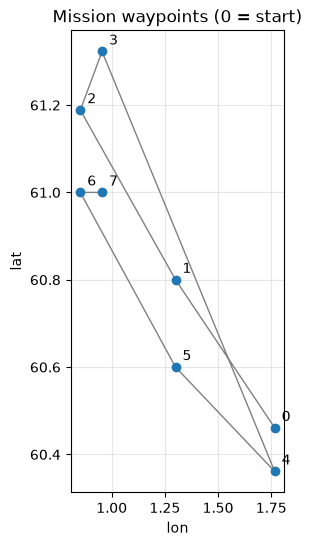

In [4]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(wps.lon, wps.lat, "-", color="grey", lw=1)
ax.scatter(wps.lon, wps.lat, color="C0", zorder=3)
for i, r in wps.iterrows():
    ax.annotate(str(i), (r.lon, r.lat), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title("Mission waypoints (0 = start)")
ax.set_aspect(1 / np.cos(np.radians(wps.lat.mean())))
ax.grid(alpha=0.3)
plt.show()

## 2. Solar forecast along the mission

P_solar = k · G, with k = 0.164 m² (`pb.K_SOLAR`, nb 10 section 4) and G = irradiance in W/m².

- **Plan input:** Open-Meteo forecast (`data/weather/forecast.csv`). For mission day n (0 = start day) the plan uses
  the forecast issued n+1 days earlier (`_d1`, `_d2`, `_d3`; after day 3 it keeps `_d3`). No extra margin.
- **Reference only:** ERA5 (`data/weather/truth.csv`) = what really happened. The plan never reads it.
- One weather point (60.5N 1.5E) for the whole route.
- The mission must fit inside the weather files (now 14 Jul – 11 Sep 2025), otherwise the notebook stops with an error.
- Hourly values are means over the hour *before* the timestamp, so each point sits at the middle of its hour (−30 min).
  Then they are interpolated to 1-minute steps.

`pb.Problem(mission, fc)` (`service/problem.py`) builds the plan solar and the Starlink schedule per minute. It's the same object Part 2 uses.

In [5]:
import math

DT_MIN = 1
K_SOLAR = pb.K_SOLAR
fc = pb.read_forecast("../data/weather/forecast.csv")
era5 = pb.read_forecast("../data/weather/truth.csv")

t0 = pd.Timestamp(mission["start_time"])
t_end = t0 + pd.Timedelta(hours=legs.hours.sum())

# no silent gaps: the mission must sit inside the weather data
for name, w in [("forecast", fc), ("ERA5", era5)]:
    if t0 < w.index[0] or t_end > w.index[-1]:
        raise ValueError(f"Mission {t0:%d %b %H:%M} -> {t_end:%d %b %H:%M} runs outside the {name} data "
                         f"({w.index[0]:%d %b %H:%M} -> {w.index[-1]:%d %b %H:%M}). "
                         f"Fetch more days: .venv/bin/python sim/fetch_weather.py --days N")

problem = pb.Problem(mission, fc)          # route, plan solar, Starlink (service/problem.py)

def era5_solar(t):
    s = era5["shortwave_radiation"]
    return K_SOLAR * s.reindex(s.index.union(t)).interpolate(method="time").reindex(t).values

t = pd.date_range(t0, t_end, freq=f"{DT_MIN}min")
sim = pd.DataFrame({"P_solar_plan": problem.p_solar[:len(t)], "P_solar_era5": era5_solar(t)}, index=t)
e_plan = sim.P_solar_plan.sum() * DT_MIN / 60 / 1000
e_era5 = sim.P_solar_era5.sum() * DT_MIN / 60 / 1000
print(f"Solar energy over the mission: plan {e_plan:.2f} kWh, ERA5 {e_era5:.2f} kWh")

Solar energy over the mission: plan 4.16 kWh, ERA5 4.12 kWh


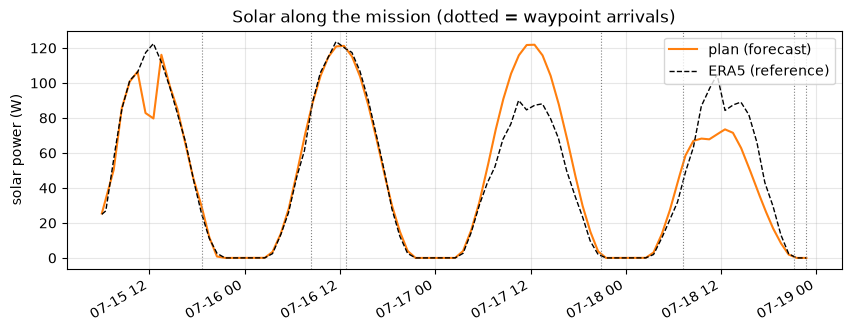

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, sim.P_solar_plan, color="C1", label="plan (forecast)")
ax.plot(sim.index, sim.P_solar_era5, color="k", ls="--", lw=1, label="ERA5 (reference)")
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("solar power (W)")
ax.set_title("Solar along the mission (dotted = waypoint arrivals)")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 3. Load along the mission

From `forecast/model.py`: load = 10 W hotel + 22 W · Starlink on (nb 06) + k_AUTO · v² (nb 08, k_AUTO = 62.7 W per (m/s)²).

- **Motor:** the mission runs in AUTO, so k = `fm.K_MODE["AUTO"]`. The whole mission is legs at `speed_ms`, so the motor is always on.
- **Starlink:** `STARLINK_SCHEDULE` (section 1.a). Default copies 15–19 Jul (nb 05): every 2 h at even hours, at :47, for 8 min.

`problem.run()` with the constant speed every hour does the whole thing (load, power and battery, through model.py)
and stops at arrival. Sections 3–5 just look at its columns.

In [7]:
print(f"motor at {speed} m/s = {pb.K_AUTO * speed ** 2:.1f} W (k·v², AUTO)")

_, run, status = problem.run([speed] * math.ceil(legs.hours.sum()), problem.start_state())   # <- the planner's run
sim = sim.join(run.drop(columns="P_solar"), how="inner")
sim["P_hotel"] = fm.HOTEL_W
sim["P_starlink"] = fm.STARLINK_W * sim.starlink
print(f"Run: {status}, {len(sim)} min")

e = sim[["P_hotel", "P_starlink", "P_motor", "P_load"]].sum() * DT_MIN / 60 / 1000
print(f"Load energy over the mission: " + ", ".join(f"{c[2:]} {v:.2f}" for c, v in e.items()) + " kWh")
print(f"Starlink on {int(sim.starlink.sum())} min in {len(sim)} min ({sim.starlink.mean():.1%})")

motor at 1.0 m/s = 62.7 W (k·v², AUTO)
Run: arrived, 5326 min
Load energy over the mission: hotel 0.89, starlink 0.13, motor 5.57, load 6.58 kWh
Starlink on 352 min in 5326 min (6.6%)


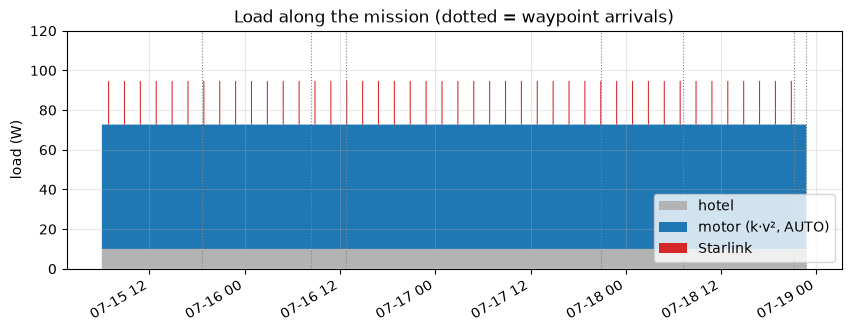

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.stackplot(sim.index, sim.P_hotel, sim.P_motor, sim.P_starlink,
             labels=["hotel", "motor (k·v², AUTO)", "Starlink"], colors=["0.7", "C0", "C3"], step="post")
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("load (W)")
ax.set_ylim(0, 120)
ax.set_title("Load along the mission (dotted = waypoint arrivals)")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 4. Total power

Battery model B1 (nb 11, `fm.BATT`). Power into the battery, before the 25 V charge cap:

P_net = η · P_solar − P_load − P_drain, with η = 1.138 and P_drain = −0.312 W (both fitted in nb 11; η > 1 is not physical, see the nb 11 notes).

In [9]:
B = fm.BATT
sim["P_net"] = B["eta"] * sim.P_solar_plan - sim.P_load - B["p_drain"]

e_net = sim.P_net.sum() * DT_MIN / 60 / 1000
print(f"Net energy over the mission: {e_net:+.2f} kWh "
      f"(solar into battery {B['eta'] * e_plan:.2f}, load {sim.P_load.sum() * DT_MIN / 60 / 1000:.2f})")
print(f"Positive (charging) {(sim.P_net > 0).mean():.0%} of the time, peak {sim.P_net.max():+.0f} W, lowest {sim.P_net.min():+.0f} W")

Net energy over the mission: -1.82 kWh (solar into battery 4.73, load 6.58)
Positive (charging) 38% of the time, peak +66 W, lowest -94 W


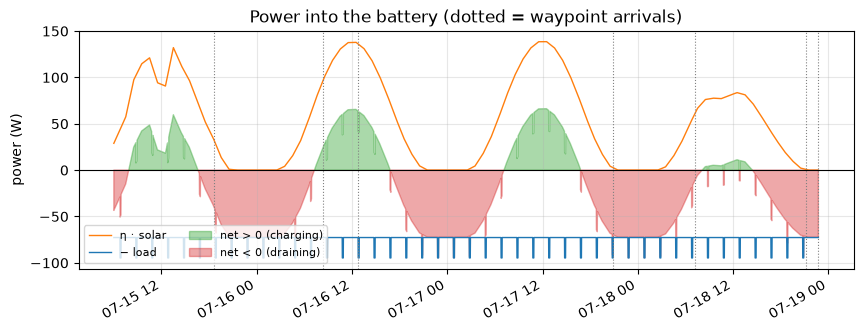

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, B["eta"] * sim.P_solar_plan, color="C1", lw=1, label="η · solar")
ax.plot(sim.index, -sim.P_load, color="C0", lw=1, label="− load")
ax.fill_between(sim.index, 0, sim.P_net, where=sim.P_net > 0, color="C2", alpha=0.4, label="net > 0 (charging)")
ax.fill_between(sim.index, 0, sim.P_net, where=sim.P_net <= 0, color="C3", alpha=0.4, label="net < 0 (draining)")
ax.axhline(0, color="k", lw=0.8)
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("power (W)")
ax.set_title("Power into the battery (dotted = waypoint arrivals)")
ax.legend(loc="lower left", fontsize=8, ncol=2)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 5. Battery voltage (rollout)

The `V` and `OCV` columns of the run in section 3 (model.py's `forecast()`, the same steps as `forecast.py`):
- OCV += P_net · dt / k, k = 420.3 Wh per volt
- terminal V = OCV + R · I, with I = P_net / OCV and R = 39.2 mΩ
- no charging above 25.0 V (extra solar is lost)
- start: `START_V` is the measured terminal voltage; the first OCV = START_V − R · I of the first minute
- no "empty" floor (model.py has none): below ~20 V the numbers only mean "flat"

No replanning: the boat follows the legs whatever happens. The reserve is only drawn as a line here.

In [11]:
reserve = mission["reserve_v"]
i_min = sim.V.idxmin()
print(f"Start {START_V:.2f} V -> end {sim.V.iloc[-1]:.2f} V (OCV {sim.OCV.iloc[-1]:.2f} V)")
print(f"Lowest {sim.V.min():.2f} V at {i_min:%d %b %H:%M}, reserve {reserve:.2f} V")
print(f"Minutes under the reserve: {(sim.V < reserve).sum()}")

Start 24.35 V -> end 19.94 V (OCV 20.08 V)
Lowest 19.94 V at 18 Jul 22:45, reserve 23.00 V
Minutes under the reserve: 3030


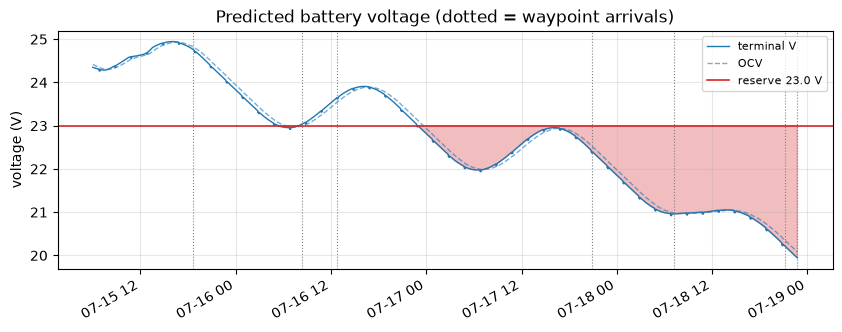

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(sim.index, sim.V, color="C0", lw=1, label="terminal V")
ax.plot(sim.index, sim.OCV, color="C0", lw=1, ls="--", alpha=0.6, label="OCV")
ax.axhline(reserve, color="C3", lw=1.2, label=f"reserve {reserve} V")
ax.fill_between(sim.index, sim.V, reserve, where=sim.V < reserve, color="C3", alpha=0.3)
for a in legs.arrive:
    ax.axvline(a, color="grey", lw=0.8, ls=":")
ax.set_ylabel("voltage (V)")
ax.set_title("Predicted battery voltage (dotted = waypoint arrivals)")
ax.legend(loc="upper right", fontsize=8)
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

# Part 2: planners

## 6. The problem

`pb.Problem` (in `service/problem.py`) holds everything that does not change between planners: route, start,
plan solar (forecast), Starlink. `run()` turns hourly speeds into per-minute inputs and hands them to
**`fm.forecast()`** (model.py), then cuts the result at arrival. Load and battery are model.py's.

- **A plan** = list of hourly speeds, each from `SPEEDS` (0.0, 0.2, … 1.4 m/s; 1.5 is not on the 0.2 grid).
  v = 0 means motor off (hotel + Starlink only); otherwise AUTO, k·v².
- **Distance** is added up minute by minute; the mission ends when it reaches the route length.
- **Deadline:** if `arrive_by` is set, plans are `n_hours` long (start → deadline, rounded down to whole hours).
- **Feasible** = arrives before the plan (or the weather data, or the deadline) runs out, and V ≥ `reserve_v` until arrival.
- **State** = `{v0, ocv, km}`. The first run starts from the measured voltage (`v0`); a run that continues
  an earlier one starts from its OCV (`ocv`). So planners can try "what if" pieces of a plan from any hour.
- `evaluate()` runs a whole plan from the start and returns the minute table + a summary.

`problem` was already made in section 2.

In [13]:
SPEEDS = pl.SPEEDS
print("SPEEDS:", SPEEDS)
print(f"Route {problem.route_km:.1f} km, start {problem.t0:%d %b %H:%M} at {problem.start_v:.2f} V, reserve {problem.reserve} V, "
      f"horizon {problem.horizon_h} h (end of the forecast)")
if problem.deadline is not None:
    print(f"Deadline {problem.deadline:%d %b %H:%M} -> plans are {problem.n_hours} h long, "
          f"average speed needed {problem.route_km * 1000 / problem.n_hours / 3600:.2f} m/s")

SPEEDS: [0.  0.2 0.4 0.6 0.8 1.  1.2 1.4]
Route 319.5 km, start 15 Jul 06:00 at 24.35 V, reserve 23.0 V, horizon 1408 h (end of the forecast)
Deadline 22 Jul 12:00 -> plans are 174 h long, average speed needed 0.51 m/s


## 7. Planners

Every planner is a class in `service/planner.py` with `solve(problem)` → list of hourly speeds. Nothing else.
To add a heuristic: write a new class there, then put it in the list in section 8. The boat uses ShiftEnergy
when the mission has `arrive_by`, SlowDown otherwise (`make_plan`).

- **ConstantSpeed** = your manual method: the fastest single speed from `SPEEDS` that arrives with V ≥ reserve.
  With a deadline: the slowest grid speed that still arrives on time (route ÷ hours, rounded up to the grid).
- **SlowDown(nominal, v_min)**: follow the mission speed, slow down only where the battery needs it.
  1. every hour at `nominal` (the mission speed, default 1.0 m/s)
  2. simulate; find the first minute under the reserve
  3. take the **latest hour before it** that is still above `v_min` and lower it by one step (−0.2)
  4. repeat until feasible, or nothing is left to slow down (= infeasible with these limits)

  Never faster than `nominal`, never slower than `v_min` (default 0.4 m/s ≈ measured drift, so the boat never just drifts).
  Latest hour first, because energy saved right before the problem is not lost to the 25 V cap.
- **Greedy(lookahead_h)**: the old heuristic (fastest speed that survives `lookahead_h` h of drift). Kept for comparison.
- **ShiftEnergy(v_min, v_max)** (needs `arrive_by`): goal = **highest lowest voltage**, arriving on time.
  1. start from the constant on-time plan
  2. simulate; find the hour of the lowest voltage (`h_worst`)
  3. **take** 0.2 m/s from an hour at or before `h_worst` (latest first, if above `v_min`)
  4. if the plan no longer arrives on time, **give** 0.2 m/s to the hour with the highest voltage
     (below `v_max`, and either after `h_worst` or at the 25 V cap, where the energy is free)
  5. keep the move only if the lowest voltage goes up; stop when no move helps

  SlowDown and Greedy still aim for the earliest arrival; with a deadline they are only checked against it.

In [14]:
import time
from planner import ConstantSpeed, Greedy, SlowDown, ShiftEnergy

## 8. Compare the planners

`compare(problem, planners)` runs each planner, evaluates its plan with the same `Problem`, and shows a table + plot.
Call it with any list, e.g. `compare(problem, [SlowDown(v_min=0.2), SlowDown(v_min=0.6)])`.

In [15]:
def compare(problem, planners, plot=True):
    results = {}
    for p in planners:
        tic = time.time()
        plan = p.solve(problem)
        df, summary = problem.evaluate(plan)
        summary["solve_s"] = round(time.time() - tic, 1)
        summary["mean_v"] = round(df.v.mean(), 2)
        summary["min_v"] = df.v.min()
        summary["max_v"] = df.v.max()
        summary["iterations"] = getattr(p, "iterations", None)
        results[p.name] = (plan, df, summary)

    if plot:
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
        for i, (name, (plan, df, s)) in enumerate(results.items()):
            hourly_t = problem.t0 + pd.to_timedelta(np.arange(len(plan)), unit="h")
            lw = 3 if name.startswith("shift-energy") else 1          # the one the boat uses (with arrive_by)
            ax1.step(hourly_t, plan, where="post", color=f"C{i}", lw=lw, label=name)
            ax2.plot(df.index, df.V, color=f"C{i}", lw=lw, label=name)
            if s["feasible"]:
                ax2.axvline(s["arrival"], color=f"C{i}", ls=":", lw=lw)
        ax2.axhline(problem.reserve, color="C3", lw=1.2, label=f"reserve {problem.reserve} V")
        if problem.deadline is not None:
            for ax in (ax1, ax2):
                ax.axvline(problem.deadline, color="k", lw=1.5, ls="--")
            ax2.text(problem.deadline, ax2.get_ylim()[1], " deadline", va="top", fontsize=8)
        ax1.set_ylabel("speed (m/s)")
        ax1.set_ylim(-0.05, 1.5)
        ax1.set_title("Hourly speed plan per planner")
        ax1.legend(fontsize=8)
        ax2.set_ylabel("voltage (V)")
        ax2.set_title("Predicted voltage (dotted = arrival, dashed = deadline)")
        ax2.legend(fontsize=8)
        for ax in (ax1, ax2):
            ax.grid(alpha=0.3)
        fig.autofmt_xdate()
        plt.show()

    table = pd.DataFrame({name: r[2] for name, r in results.items()}).T
    return table, results

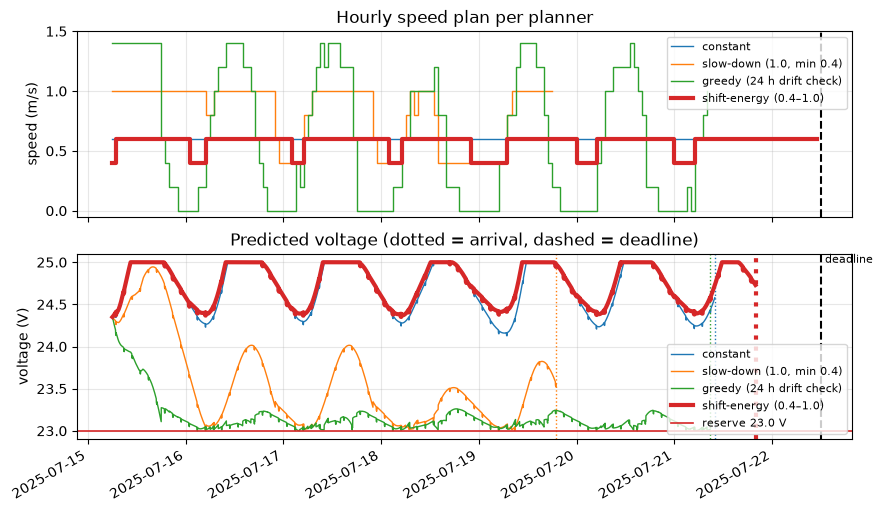

,status,arrival,hours,min_V,end_V,min_under_reserve,on_time,feasible,solve_s,mean_v,min_v,max_v,iterations
constant,arrived,2025-07-21 09:55:00+00:00,147.933333,24.126887,24.578419,0,True,True,0.0,0.6,0.6,0.6,None
"slow-down (1.0, min 0.4)",arrived,2025-07-19 18:57:00+00:00,108.966667,23.00156,23.550548,0,True,True,14.8,0.81,0.4,1.0,102
greedy (24 h drift check),arrived,2025-07-21 08:45:00+00:00,146.766667,23.000026,23.014585,0,True,True,4.2,0.6,0.0,1.4,None
shift-energy (0.4–1.0),arrived,2025-07-21 19:55:00+00:00,157.933333,24.350009,24.729642,0,True,True,0.6,0.56,0.4,0.6,31


In [16]:
table, results = compare(problem, [ConstantSpeed(), SlowDown(nominal=1.0, v_min=0.4), Greedy(lookahead_h=24),
                                  ShiftEnergy(v_min=0.4, v_max=1.0)], plot=True)
table

## 9. Predicted vs actual voltage

Uses the **shift-energy** plan from section 8. Same hourly speeds, same Starlink, same load and battery model.
The only change is the solar input:
- **predicted** = plan solar (Open-Meteo forecast), as the planner saw it
- **actual** = ERA5 solar × 0.164 (what really happened, the reference from section 2)

So the gap between the two lines is just the forecast error in the weather, carried through the battery.

Plan: shift-energy (0.4–1.0), 174 h
Solar over the run: predicted 6.89 kWh, actual 7.11 kWh
Lowest V: predicted 24.35, actual 24.31 (reserve 23.0)
End V: predicted 24.73, actual 24.82
Error (pred − act): mean -0.00 V, RMSE 0.07 V, largest 0.31 V; actual under reserve 0 min


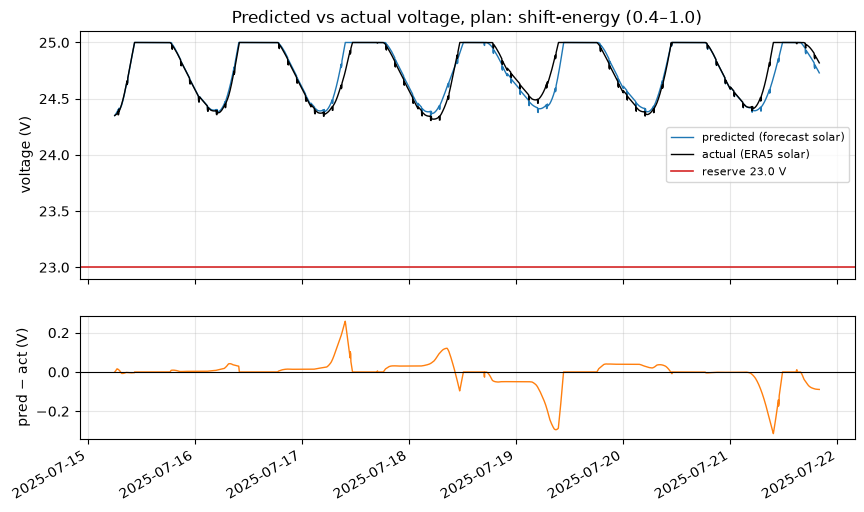

In [17]:
import copy

PLAN_NAME = [n for n in results if n.startswith("shift-energy")][0]
plan, df_pred, s_pred = results[PLAN_NAME]

# same problem, ERA5 solar instead of the forecast (model.py still does the run)
actual = copy.copy(problem)
actual.p_solar = K_SOLAR * era5["shortwave_radiation"].reindex(era5.index.union(problem.t)) \
                               .interpolate(method="time").reindex(problem.t).values
df_act, s_act = actual.evaluate(plan)

both = pd.DataFrame({"pred": df_pred.V, "act": df_act.V}).dropna()
err = both.pred - both.act
print(f"Plan: {PLAN_NAME}, {len(plan)} h")
print(f"Solar over the run: predicted {df_pred.P_solar.sum() / 60 / 1000:.2f} kWh, actual {df_act.P_solar.sum() / 60 / 1000:.2f} kWh")
print(f"Lowest V: predicted {s_pred['min_V']:.2f}, actual {s_act['min_V']:.2f} (reserve {problem.reserve})")
print(f"End V: predicted {df_pred.V.iloc[-1]:.2f}, actual {df_act.V.iloc[-1]:.2f}")
print(f"Error (pred − act): mean {err.mean():+.2f} V, RMSE {np.sqrt((err ** 2).mean()):.2f} V, "
      f"largest {err.abs().max():.2f} V; actual under reserve {s_act['min_under_reserve']} min")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(df_pred.index, df_pred.V, color="C0", lw=1, label="predicted (forecast solar)")
ax1.plot(df_act.index, df_act.V, color="k", lw=1, label="actual (ERA5 solar)")
ax1.axhline(problem.reserve, color="C3", lw=1.2, label=f"reserve {problem.reserve} V")
ax1.set_ylabel("voltage (V)")
ax1.set_title(f"Predicted vs actual voltage, plan: {PLAN_NAME}")
ax1.legend(fontsize=8)
ax2.plot(both.index, err, color="C1", lw=1)
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("pred − act (V)")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()

## 10. Replanning when the voltage drifts

Same planner (shift-energy), same forecast, same mission. We now go through time minute by minute:
- **actual** = the boat in the ERA5 world (section 9), following the current plan
- **predicted** = what the current plan expected, with the forecast solar
- when |predicted − actual| > `REPLAN_GAP_V`, we **replan** at that minute:
  the planner starts from the *actual* battery state (its OCV) and the distance still to go,
  with the **same forecast** for the rest of the mission and the same deadline
- a replan also happens if the plan runs out before the boat really arrives

Hourly speeds restart at each replan time. `MAX_REPLANS` stops the loop if it keeps firing.
Note: terminal V = OCV + R·I, so a sudden solar error moves it at once (R · ΔP / V ≈ 0.04 V per 25 W).

0 replans in 1 s, threshold 0.5 V
Arrival 21 Jul 19:55, deadline 22 Jul 12:00
Lowest actual V: with replanning 24.31, without 24.31 (reserve 23.0)


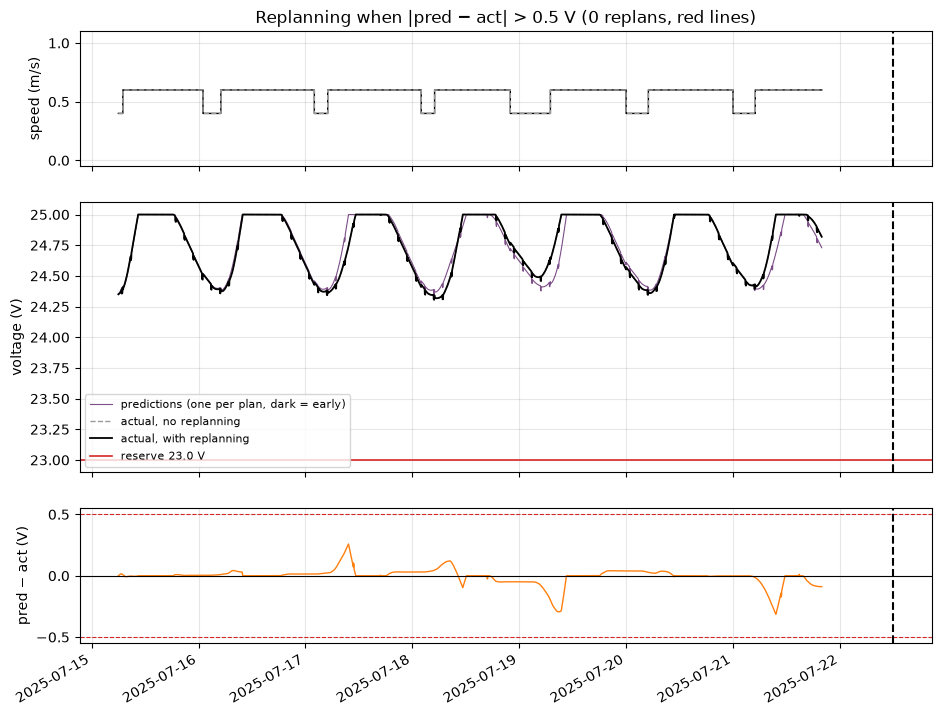

In [18]:
REPLAN_GAP_V = 0.5
MAX_REPLANS = 200

def from_here(base, idx, state):
    """Copy of `base` that starts at minute idx, from this battery state, with the distance still to go.
    The solar/Starlink arrays are sliced, so the forecast stays the one the first plan used."""
    sp = copy.copy(base)
    sp.t0 = base.t[idx]
    sp.t = base.t[idx:]
    sp.p_solar, sp.starlink = base.p_solar[idx:], base.starlink[idx:]
    sp.horizon_h = len(sp.t) // 60
    sp.route_km = base.route_km - state["km"]
    if base.deadline is not None:
        sp.n_hours = max(1, int((base.deadline - sp.t0) / pd.Timedelta(hours=1)))
    else:
        sp.n_hours = sp.horizon_h
    sp.start_state = lambda: dict(state, km=0.0)          # measured V at the start, then the OCV
    return sp

planner = ShiftEnergy(v_min=0.4, v_max=1.0)
idx, state = 0, problem.start_state()
segments, replans, act_parts = [], [], []
tic = time.time()
while True:
    pp, pa = from_here(problem, idx, state), from_here(actual, idx, state)
    plan_i = planner.solve(pp)
    _, dp, _ = pp.run(plan_i, pp.start_state())
    _, da, st_a = pa.run(plan_i, pa.start_state())
    dp["km"] += state["km"]; da["km"] += state["km"]
    segments.append({"start": pp.t0, "plan": plan_i, "pred": dp})

    n = min(len(dp), len(da))
    gap = np.abs(dp.V.values[:n] - da.V.values[:n])
    hit = np.nonzero(gap[1:] > REPLAN_GAP_V)[0]               # skip minute 0 (same state by construction)
    if len(hit):
        m, why = hit[0] + 1, "gap"
    elif st_a in ("arrived", "out_of_data") or len(da) <= 1:
        act_parts.append(da)
        break
    else:
        m, why = len(da) - 1, "plan ran out"
    if len(replans) >= MAX_REPLANS:
        act_parts.append(da)
        print(f"Stopped after MAX_REPLANS = {MAX_REPLANS}")
        break

    act_parts.append(da.iloc[:m + 1])
    r = da.iloc[m]
    state = {"v0": None, "ocv": r.OCV, "km": r.km}
    idx += m + 1
    replans.append({"t": da.index[m], "why": why, "V_actual": r.V, "V_predicted": dp.V.iloc[m],
                    "gap": dp.V.iloc[m] - r.V, "km_done": r.km})

df_loop = pd.concat(act_parts)
arrived = df_loop.km.iloc[-1] >= problem.route_km - 1e-6
print(f"{len(replans)} replans in {time.time() - tic:.0f} s, threshold {REPLAN_GAP_V} V")
print(f"Arrival {df_loop.index[-1]:%d %b %H:%M}" + ("" if arrived else " (NOT arrived)") +
      (f", deadline {problem.deadline:%d %b %H:%M}" if problem.deadline is not None else ""))
print(f"Lowest actual V: with replanning {df_loop.V.min():.2f}, without {s_act['min_V']:.2f} (reserve {problem.reserve})")

# new prediction after each replan: lowest V it expects, arrival it expects, its first speeds
for rp, seg in zip(replans, segments[1:]):
    rp["new_pred_min_V"] = seg["pred"].V.min()
    rp["new_pred_arrival"] = seg["pred"].index[-1]
    rp["new_first_speeds"] = " ".join(f"{v:.1f}" for v in seg["plan"][:6])
pd.DataFrame(replans).round({c: 3 for c in ["V_actual", "V_predicted", "gap", "km_done", "new_pred_min_V"]})

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(11, 9), sharex=True, gridspec_kw={"height_ratios": [1, 2, 1]})

ax1.step(df_loop.index, df_loop.v, where="post", color="k", lw=1, label="speed with replanning")
ax1.step(df_act.index, df_act.v, where="post", color="0.6", lw=1, ls="--", label="first plan (no replanning)")
ax1.set_ylabel("speed (m/s)"); ax1.set_ylim(-0.05, 1.1)
ax1.set_title(f"Replanning when |pred − act| > {REPLAN_GAP_V} V ({len(replans)} replans, red lines)")

cmap = plt.get_cmap("viridis")
for i, seg in enumerate(segments):
    ax2.plot(seg["pred"].index, seg["pred"].V, color=cmap(i / max(1, len(segments) - 1)), lw=0.8, alpha=0.7,
             label="predictions (one per plan, dark = early)" if i == 0 else None)
ax2.plot(df_act.index, df_act.V, color="0.6", lw=1, ls="--", label="actual, no replanning")
ax2.plot(df_loop.index, df_loop.V, color="k", lw=1.3, label="actual, with replanning")
rp = pd.DataFrame(replans)
if len(rp):
    ax2.scatter(rp.t, rp.V_actual, color="C3", s=14, zorder=5, label="replan")
ax2.axhline(problem.reserve, color="C3", lw=1.2, label=f"reserve {problem.reserve} V")
ax2.set_ylabel("voltage (V)"); ax2.legend(fontsize=8, loc="lower left")

# gap of the plan that was active at each minute
pred_active = pd.concat([seg["pred"].V.loc[part.index] for seg, part in zip(segments, act_parts)])
ax3.plot(df_loop.index, pred_active - df_loop.V, color="C1", lw=1)
for y in (REPLAN_GAP_V, -REPLAN_GAP_V):
    ax3.axhline(y, color="C3", lw=0.8, ls="--")
ax3.axhline(0, color="k", lw=0.8)
ax3.set_ylabel("pred − act (V)")

for ax in (ax1, ax2, ax3):
    for t_r in rp.get("t", []):
        ax.axvline(t_r, color="C3", lw=0.5, alpha=0.5)
    if problem.deadline is not None:
        ax.axvline(problem.deadline, color="k", lw=1.5, ls="--")
    ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.show()